In [1]:
import os, sys, random, json
from pathlib import Path
from multiprocessing import Pool
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
import rl_utils as U

RAW = PROJECT.parent / "ESA_Mission1_Selected"
OUT = PROJECT / "outputs"
for d in ["01_dataset", "02_preprocessing", "03_splits", "04_plots"]:
    (OUT / d).mkdir(parents=True, exist_ok=True)
PLOTS = OUT / "04_plots"

SEED = 42
random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3})

def save_show(name):
    plt.tight_layout(); plt.savefig(PLOTS / name, bbox_inches="tight"); plt.close()
    display(Image(filename=str(PLOTS / name)))

SELECTED_CHANNELS = ["channel_41", "channel_45", "channel_43", "channel_14", "channel_21", "channel_29",
                     "channel_48", "channel_52", "channel_31", "channel_22", "channel_39", "channel_15"]
print("Raw data folder:", RAW, "| exists:", RAW.exists())
print("Selected channels:", len(SELECTED_CHANNELS))

Raw data folder: /home/claude/RL_Project/ESA_Mission1_Selected | exists: True
Selected channels: 12


## 1. Channel metadata and anomaly annotations

In [2]:
channels_meta = pd.read_csv(RAW / "channels.csv")
labels = pd.read_csv(RAW / "labels.csv")
labels["StartTime"] = pd.to_datetime(labels["StartTime"], utc=True, format="mixed").dt.tz_localize(None)
labels["EndTime"] = pd.to_datetime(labels["EndTime"], utc=True, format="mixed").dt.tz_localize(None)

sel_meta = channels_meta[channels_meta["Channel"].isin(SELECTED_CHANNELS)].reset_index(drop=True)
sel_labels = labels[labels["Channel"].isin(SELECTED_CHANNELS)].copy().reset_index(drop=True)
sel_labels["Duration_min"] = (sel_labels["EndTime"] - sel_labels["StartTime"]).dt.total_seconds() / 60

print(sel_meta.to_string(index=False))
print("\nAnnotation records:", len(sel_labels))
print("Anomaly events (IDs):", sel_labels["ID"].nunique())
print("Annotation period:", sel_labels["StartTime"].min(), "->", sel_labels["EndTime"].max())

   Channel   Subsystem   Physical Unit  Group Target Categorical
channel_14 subsystem_6 physical_unit_3      4    YES          NO
channel_15 subsystem_6 physical_unit_3      7    YES          NO
channel_21 subsystem_6 physical_unit_3      4    YES          NO
channel_22 subsystem_6 physical_unit_3      7    YES          NO
channel_29 subsystem_6 physical_unit_3      4    YES          NO
channel_31 subsystem_6 physical_unit_3      7    YES          NO
channel_39 subsystem_6 physical_unit_3      7    YES          NO
channel_41 subsystem_5 physical_unit_4      8    YES          NO
channel_43 subsystem_5 physical_unit_4      8    YES          NO
channel_45 subsystem_5 physical_unit_4      8    YES          NO
channel_48 subsystem_6 physical_unit_3      9    YES          NO
channel_52 subsystem_6 physical_unit_3     10    YES          NO

Annotation records: 1306
Anomaly events (IDs): 168
Annotation period: 2000-02-10 01:31:46.347000 -> 2013-12-06 06:44:59.943000


## 2. Parallel channel alignment to the 90-second grid
Each channel is resampled (mean) to 30 s and 90 s grids to compare missingness; the 90 s series is kept.

In [3]:
jobs = [(ch, str(RAW / "channels" / f"{ch}.zip")) for ch in SELECTED_CHANNELS]
with Pool(processes=3) as pool:
    results = pool.map(U.process_channel, jobs)

grid = U.common_grid("90s")
telemetry_df = pd.DataFrame({ch: arr for ch, arr, _, _ in results}, index=grid)[SELECTED_CHANNELS]
telemetry_df.index.name = "datetime"
channel_summary = pd.DataFrame([info for _, _, info, _ in results]).set_index("Channel").loc[SELECTED_CHANNELS].reset_index()
gap_minutes = np.concatenate([g for _, _, _, g in results])
del results

pd.set_option("display.width", 200)
print(channel_summary.round(3).to_string(index=False))

   Channel  Raw_Rows  Median_Interval_s  Missing_30s_%  Missing_90s_%  Missing_Gaps_90s  Gaps_<=4.5min  Gaps_>4.5min  Longest_Gap_min  Interpolated_Values  Remaining_Missing  Remaining_Missing_%
channel_41  15381169               30.0          0.583          0.309             14447          14354            93            354.0                14404                751                0.015
channel_45  15381169               30.0          0.583          0.309             14447          14354            93            354.0                14404                751                0.015
channel_43  15381169               30.0          0.583          0.309             14447          14354            93            354.0                14404                751                0.015
channel_14   5272893               90.0         66.687          0.555              9428           9402            26            354.0                26342                923                0.019
channel_21   5272893     

## 3. Choice of the common time resolution (30 s vs 90 s)

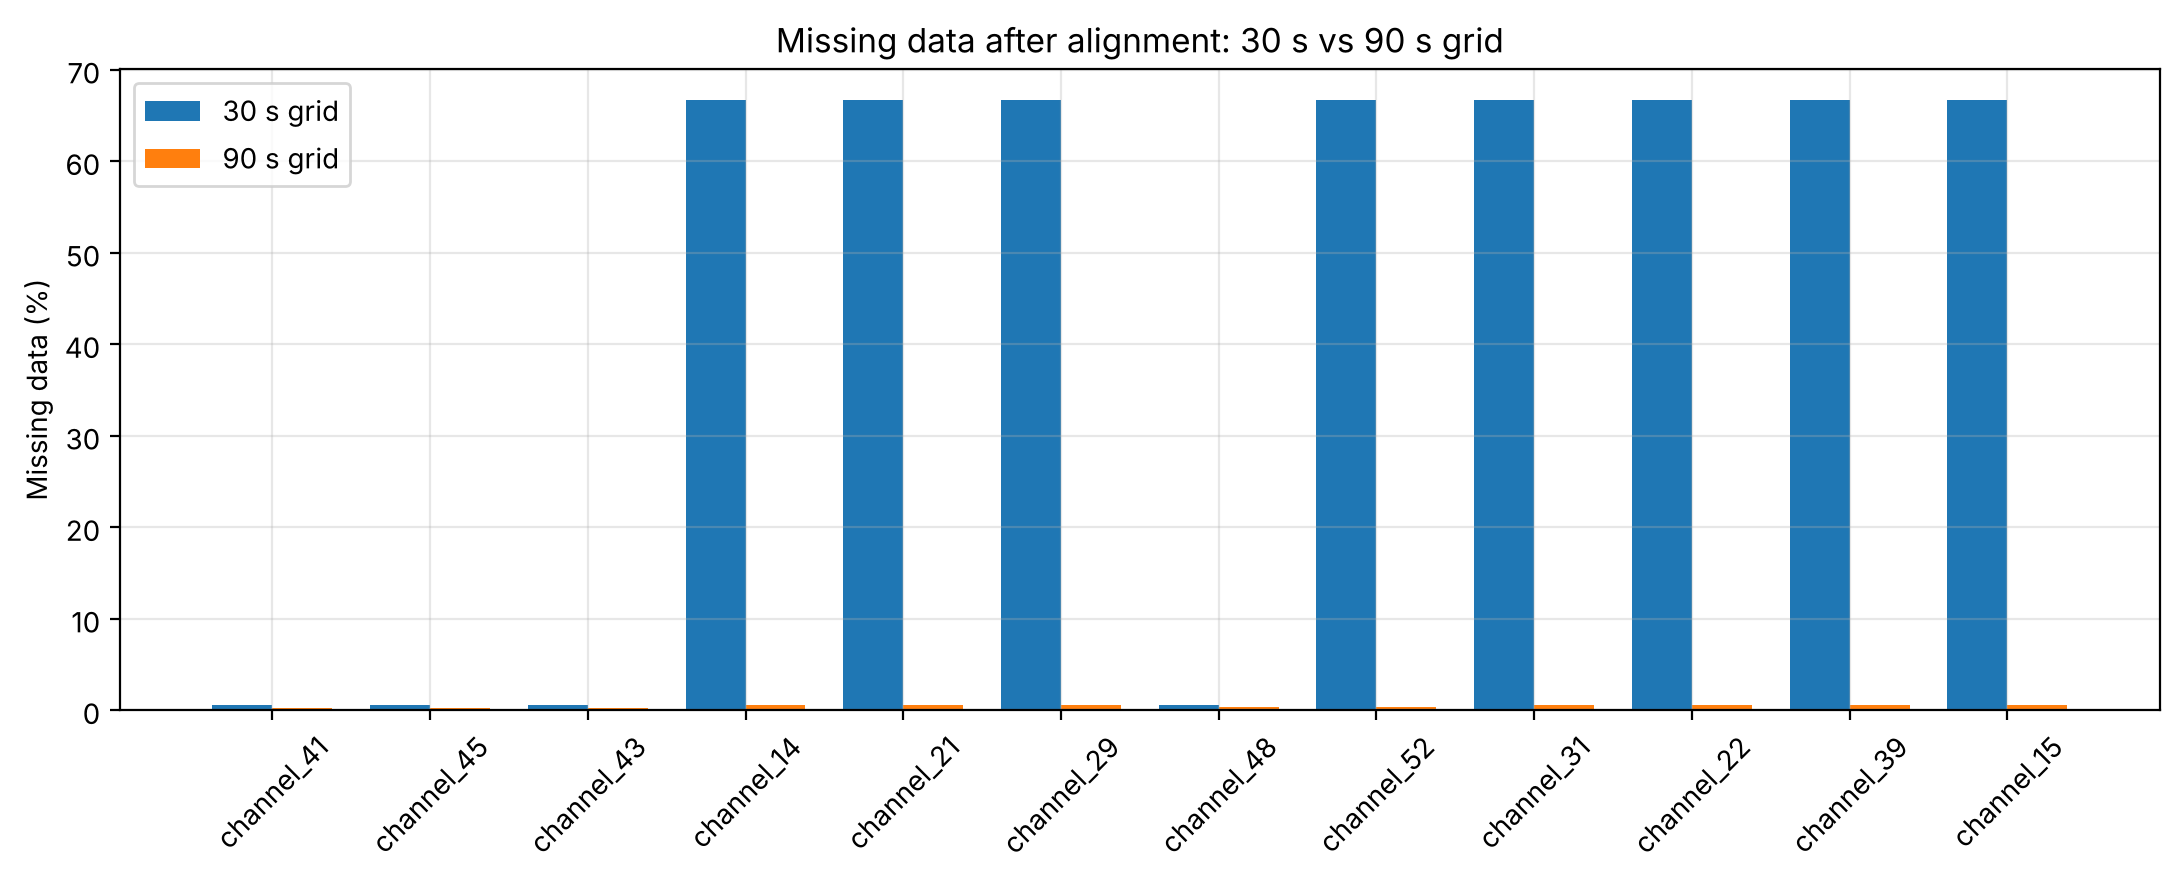

 Resolution_s  Annotations_>=_resolution  Annotation_coverage_%  Event_IDs_represented  Event_coverage_%
           30                       1154                  88.36                    155             92.26
           90                       1120                  85.76                    154             91.67

Decision: 90 s grid — 8 of 12 channels are natively ~90 s, so a 30 s grid leaves ~67 % of their samples empty,
while annotation coverage only drops from 88.4 % to 85.8 %.


In [4]:
x = np.arange(len(channel_summary)); w = 0.38
plt.figure(figsize=(11, 4.5))
plt.bar(x - w/2, channel_summary["Missing_30s_%"], w, label="30 s grid")
plt.bar(x + w/2, channel_summary["Missing_90s_%"], w, label="90 s grid")
plt.xticks(x, channel_summary["Channel"], rotation=45); plt.ylabel("Missing data (%)")
plt.title("Missing data after alignment: 30 s vs 90 s grid"); plt.legend()
save_show("01_missing_30s_vs_90s.png")

coverage = []
for res in [30, 90]:
    valid = sel_labels[sel_labels["Duration_min"] * 60 >= res]
    coverage.append({"Resolution_s": res,
                     "Annotations_>=_resolution": len(valid), "Annotation_coverage_%": round(len(valid) / len(sel_labels) * 100, 2),
                     "Event_IDs_represented": valid["ID"].nunique(),
                     "Event_coverage_%": round(valid["ID"].nunique() / sel_labels["ID"].nunique() * 100, 2)})
coverage_df = pd.DataFrame(coverage)
print(coverage_df.to_string(index=False))
print("\nDecision: 90 s grid — 8 of 12 channels are natively ~90 s, so a 30 s grid leaves ~67 % of their samples empty,"
      "\nwhile annotation coverage only drops from 88.4 % to 85.8 %.")

## 4. Missing-gap analysis and short-gap interpolation

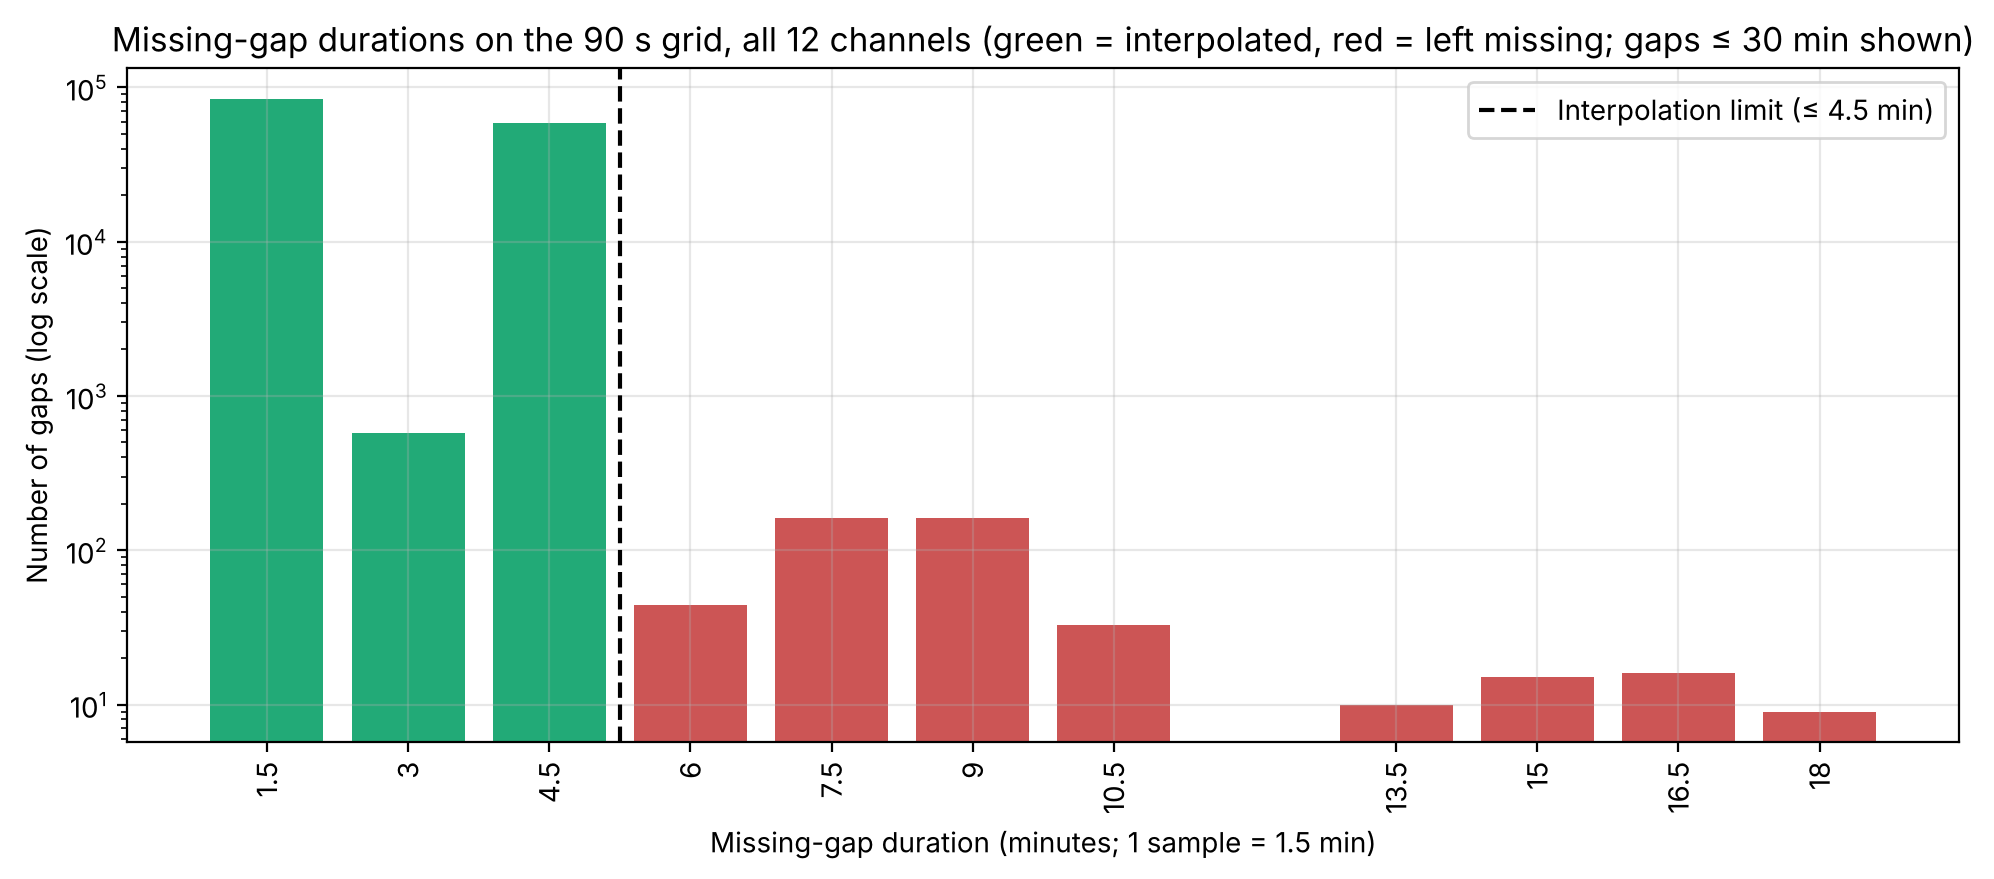

Total gaps (all channels): 144741
Gaps <= 4.5 min: 99.66 %
Longest gap: 354.0 min

Remaining missing after short-gap interpolation:
   Channel  Missing_90s_%  Interpolated_Values  Remaining_Missing  Remaining_Missing_%
channel_41         0.3087                14404                751               0.0153
channel_45         0.3087                14404                751               0.0153
channel_43         0.3087                14404                751               0.0153
channel_14         0.5554                26342                923               0.0188
channel_21         0.5554                26342                923               0.0188
channel_29         0.5554                26342                923               0.0188
channel_48         0.3754                17558                871               0.0177
channel_52         0.3837                17965                874               0.0178
channel_31         0.5554                26342                923               0.018

In [5]:
steps = np.rint(gap_minutes / 1.5).astype(int)
cnt = pd.Series(steps).value_counts().sort_index()
cnt = cnt[cnt.index <= 20]
plt.figure(figsize=(10, 4.5))
plt.bar(cnt.index * 1.5, cnt.values, width=1.2, color=["#2a7" if k <= U.MAX_INTERP_STEPS else "#c55" for k in cnt.index])
plt.yscale("log"); plt.axvline(U.MAX_INTERP_STEPS * 1.5 + 0.75, color="black", ls="--", label="Interpolation limit (≤ 4.5 min)")
plt.xticks(cnt.index * 1.5, [f"{v:g}" for v in cnt.index * 1.5], rotation=90)
plt.xlabel("Missing-gap duration (minutes; 1 sample = 1.5 min)"); plt.ylabel("Number of gaps (log scale)")
plt.title("Missing-gap durations on the 90 s grid, all 12 channels (green = interpolated, red = left missing; gaps ≤ 30 min shown)")
plt.legend()
save_show("02_missing_gap_distribution_90s.png")

print("Total gaps (all channels):", len(gap_minutes))
print("Gaps <= 4.5 min: %.2f %%" % ((gap_minutes <= 4.5).mean() * 100))
print("Longest gap: %.1f min" % gap_minutes.max())
print("\nRemaining missing after short-gap interpolation:")
print(channel_summary[["Channel", "Missing_90s_%", "Interpolated_Values", "Remaining_Missing", "Remaining_Missing_%"]].round(4).to_string(index=False))

## 5. Common 12-channel telemetry matrix

In [6]:
print("Shape:", telemetry_df.shape)
print("Range:", telemetry_df.index.min(), "->", telemetry_df.index.max())
print("Duplicate timestamps:", int(telemetry_df.index.duplicated().sum()))
print("Dtypes:", telemetry_df.dtypes.unique())
print(telemetry_df.describe().T.round(4))

Shape: (4909440, 12)
Range: 2000-01-01 00:00:00 -> 2013-12-31 23:58:30
Duplicate timestamps: 0
Dtypes: [dtype('float32')]


                count    mean     std     min     25%     50%     75%     max
channel_41  4908689.0  0.8082  0.0310  0.0000  0.8058  0.8097  0.8136  0.9813
channel_45  4908689.0  0.8104  0.0312  0.0000  0.8075  0.8118  0.8163  0.9992
channel_43  4908689.0  0.7686  0.0317  0.0000  0.7664  0.7703  0.7743  0.9494
channel_14  4908517.0  0.2721  0.0958  0.0785  0.2142  0.2595  0.3063  0.9711
channel_21  4908517.0  0.2784  0.0976  0.0739  0.2188  0.2655  0.3138  1.0000
channel_29  4908517.0  0.2911  0.0912  0.0860  0.2353  0.2821  0.3249  0.9711
channel_48  4908569.0  0.0028  0.0302  0.0000  0.0018  0.0018  0.0019  1.0000
channel_52  4908566.0  0.7556  0.0408  0.0000  0.7470  0.7566  0.7704  0.9792
channel_31  4908517.0  0.3319  0.0731  0.0155  0.2871  0.3276  0.3579  1.0000
channel_22  4908517.0  0.3335  0.0728  0.0219  0.2900  0.3290  0.3593  1.0000
channel_39  4908517.0  0.3362  0.0735  0.0309  0.2929  0.3319  0.3651  0.9718
channel_15  4908517.0  0.1210  0.0653  0.0013  0.0799  0.1185  0

## 6. Anomaly-event statistics

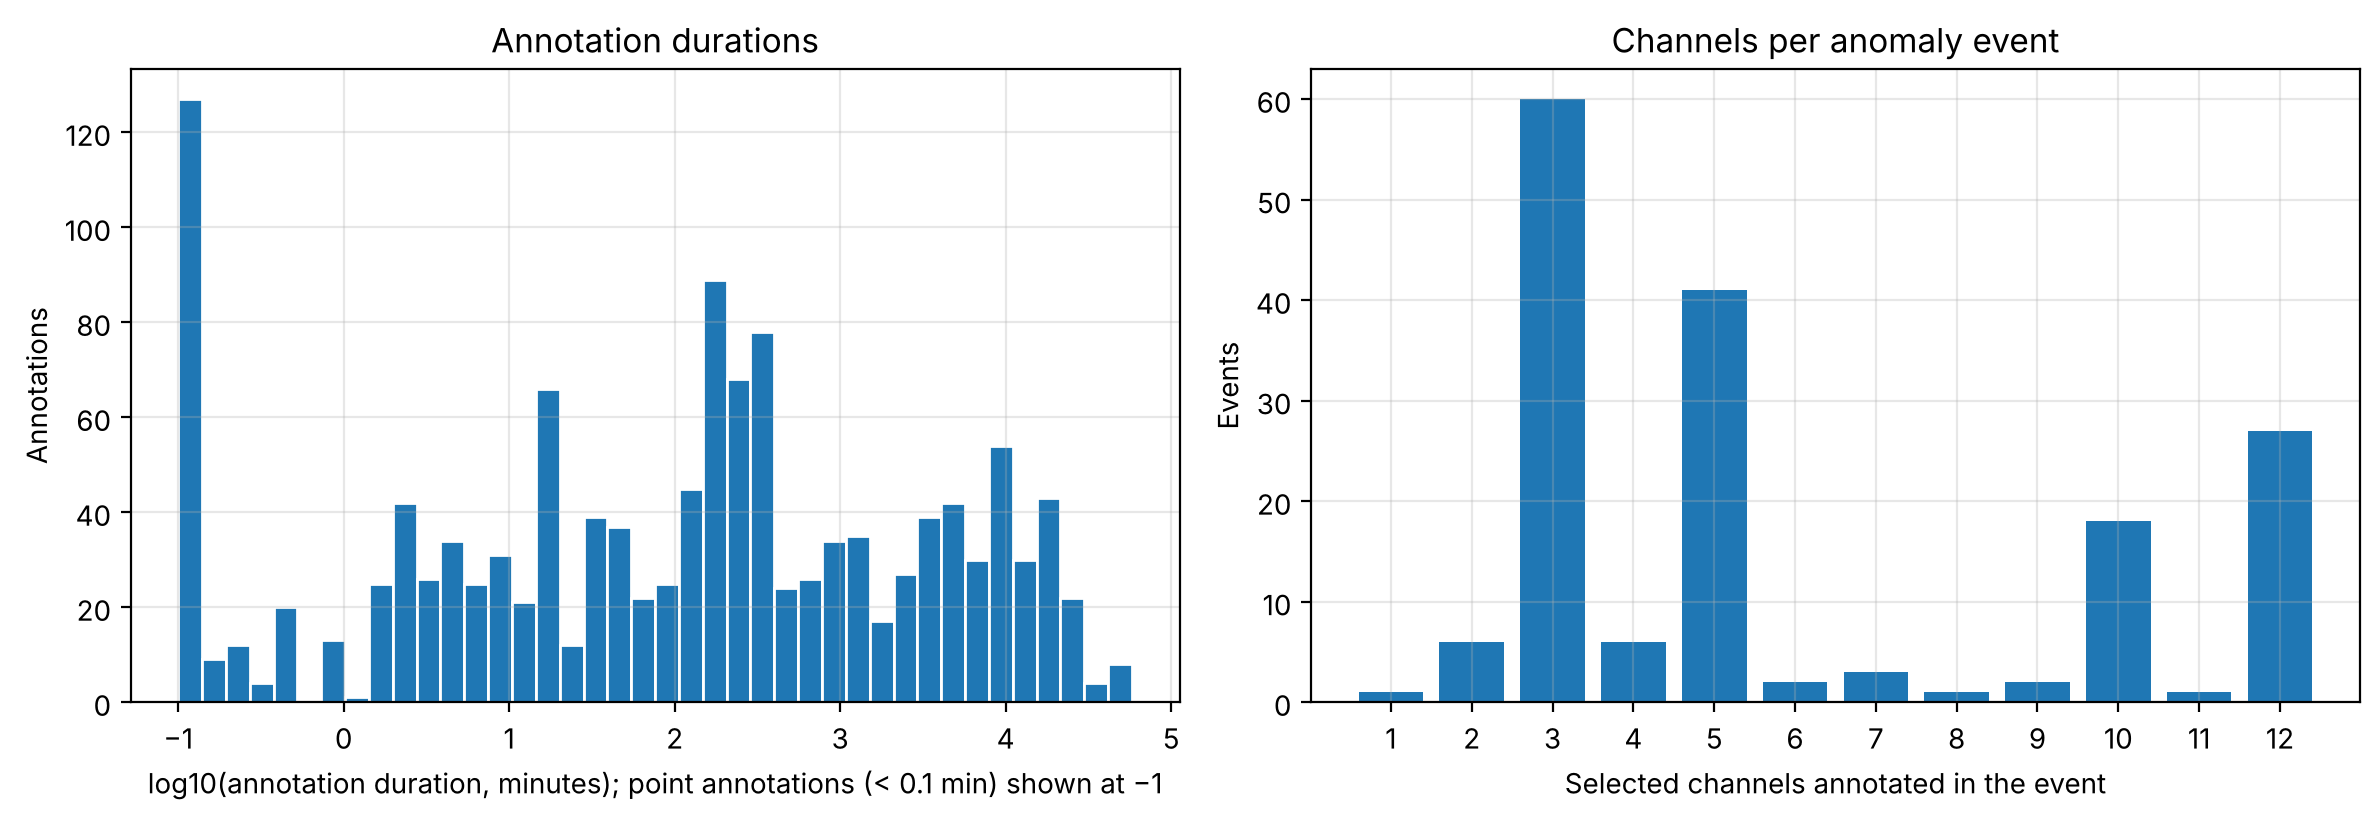

Channel
1      1
2      6
3     60
4      6
5     41
6      2
7      3
8      1
9      2
10    18
11     1
12    27


In [7]:
event_channels = sel_labels.groupby("ID")["Channel"].nunique()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(np.log10(sel_labels["Duration_min"].clip(lower=0.1)), bins=40, edgecolor="white")
ax[0].set_xlabel("log10(annotation duration, minutes); point annotations (< 0.1 min) shown at −1"); ax[0].set_ylabel("Annotations")
ax[0].set_title("Annotation durations")
vc = event_channels.value_counts().sort_index()
ax[1].bar(vc.index, vc.values); ax[1].set_xticks(range(1, 13))
ax[1].set_xlabel("Selected channels annotated in the event"); ax[1].set_ylabel("Events")
ax[1].set_title("Channels per anomaly event")
save_show("03_anomaly_event_statistics.png")
print(vc.to_string())

## 7. Event-level train / validation / test split (no leakage)

In [8]:
anomaly_ids = sorted(sel_labels["ID"].unique())
rng = random.Random(SEED); rng.shuffle(anomaly_ids)
n = len(anomaly_ids); n_train = int(n * 0.70); n_val = int(n * 0.15)
split_ids = pd.DataFrame({"ID": anomaly_ids,
                          "Split": ["Train"] * n_train + ["Validation"] * n_val + ["Test"] * (n - n_train - n_val)})
S = {s: set(split_ids.loc[split_ids.Split == s, "ID"]) for s in ["Train", "Validation", "Test"]}
assert not (S["Train"] & S["Validation"]) and not (S["Train"] & S["Test"]) and not (S["Validation"] & S["Test"])
split_summary = (sel_labels.merge(split_ids, on="ID").groupby("Split")
                 .agg(Anomaly_IDs=("ID", "nunique"), Annotation_Records=("ID", "size"))
                 .reindex(["Train", "Validation", "Test"]).reset_index())
split_summary["Record_%"] = (split_summary["Annotation_Records"] / len(sel_labels) * 100).round(2)
print(split_summary.to_string(index=False))
print("Overlap between splits: none (verified)")

     Split  Anomaly_IDs  Annotation_Records  Record_%
     Train          117                 945     72.36
Validation           25                 151     11.56
      Test           26                 210     16.08
Overlap between splits: none (verified)


## 8. Known-anomaly mask and label-clean segments
Timestamps covered by **any** annotation of the 168 events are excluded from autoencoder training.
Unannotated data is called *label-clean*, not "proven normal".

Known-anomaly timestamps: 457242 (9.314 %)
Label-clean timestamps: 4452198
Label-clean segments: 165
count     165.00
mean      674.58
std       718.93
min         0.02
25%       102.05
50%       453.85
75%      1088.70
max      4612.42
Name: Duration_hours, dtype: float64


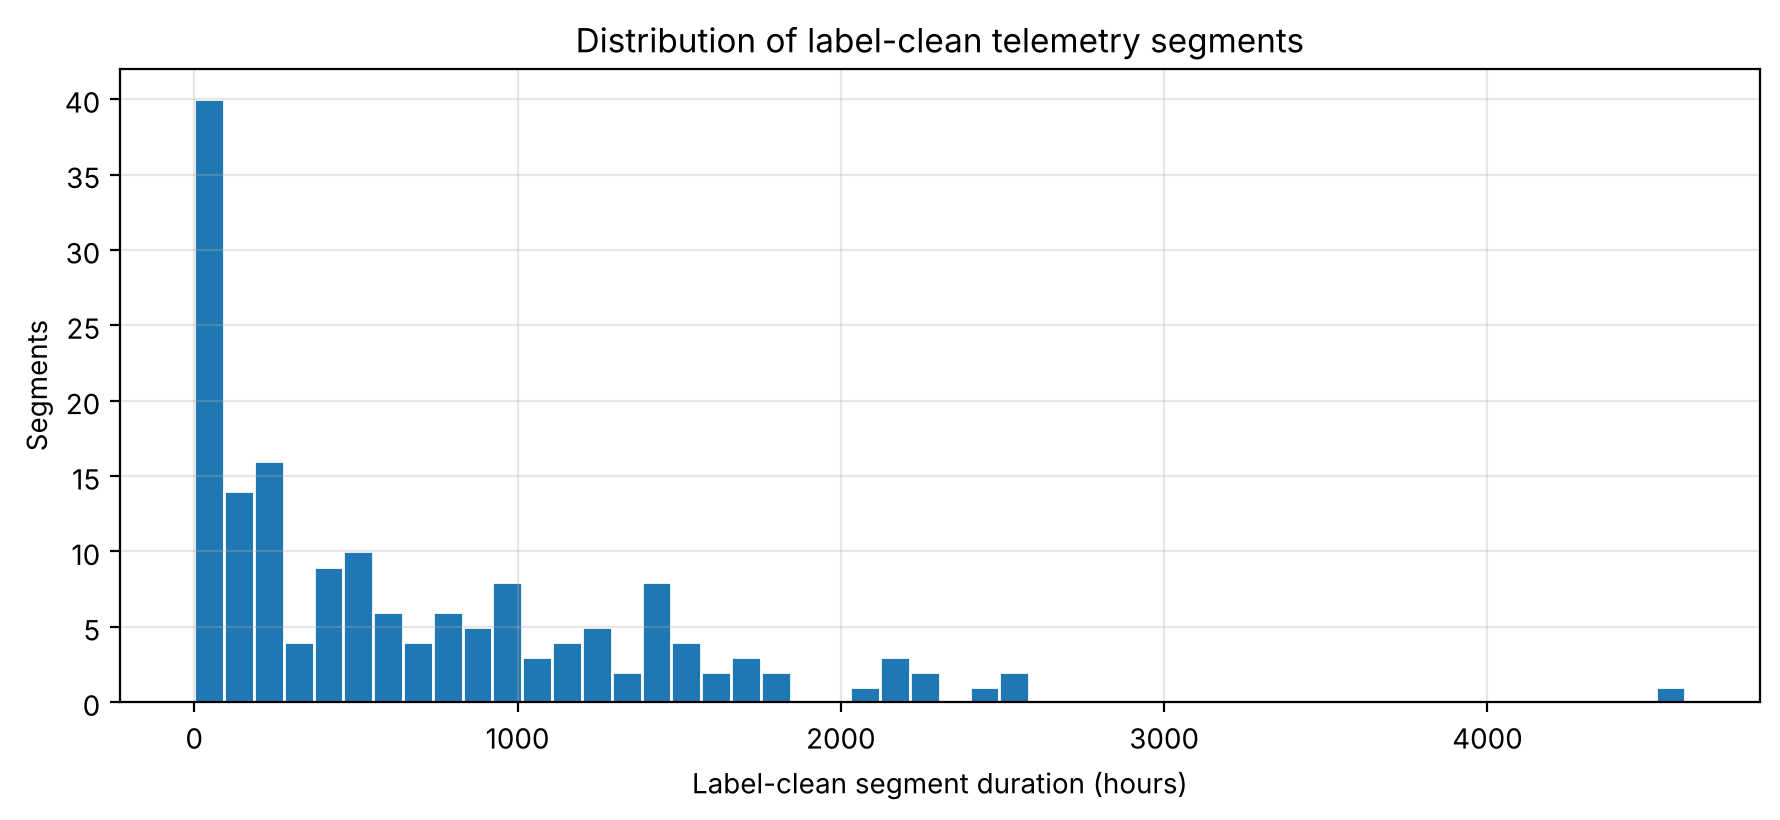

In [9]:
known_mask = U.interval_mask(telemetry_df.index, sel_labels["StartTime"].values, sel_labels["EndTime"].values)
clean = ~known_mask
d = np.diff(np.concatenate([[0], clean.astype(np.int8), [0]]))
starts, ends = np.where(d == 1)[0], np.where(d == -1)[0]
clean_segments = pd.DataFrame({"Start": telemetry_df.index[starts], "End": telemetry_df.index[ends - 1],
                               "Length": ends - starts})
clean_segments["Duration_hours"] = (clean_segments["Length"] * 1.5 / 60).round(2)
print("Known-anomaly timestamps: %d (%.3f %%)" % (known_mask.sum(), known_mask.mean() * 100))
print("Label-clean timestamps:", int(clean.sum()))
print("Label-clean segments:", len(clean_segments))
print(clean_segments["Duration_hours"].describe().round(2))

plt.figure(figsize=(9, 4.2))
plt.hist(clean_segments["Duration_hours"], bins=50, edgecolor="white")
plt.xlabel("Label-clean segment duration (hours)"); plt.ylabel("Segments")
plt.title("Distribution of label-clean telemetry segments")
save_show("04_label_clean_segment_durations.png")

## 9. LSTM window length

 Window  Hours  Usable_segments  Candidate_windows  NaN-free_windows  NaN-free_%
     64    1.6              159              69480             69480       100.0
    128    3.2              151              34694             34694       100.0
    256    6.4              147              17311             17311       100.0


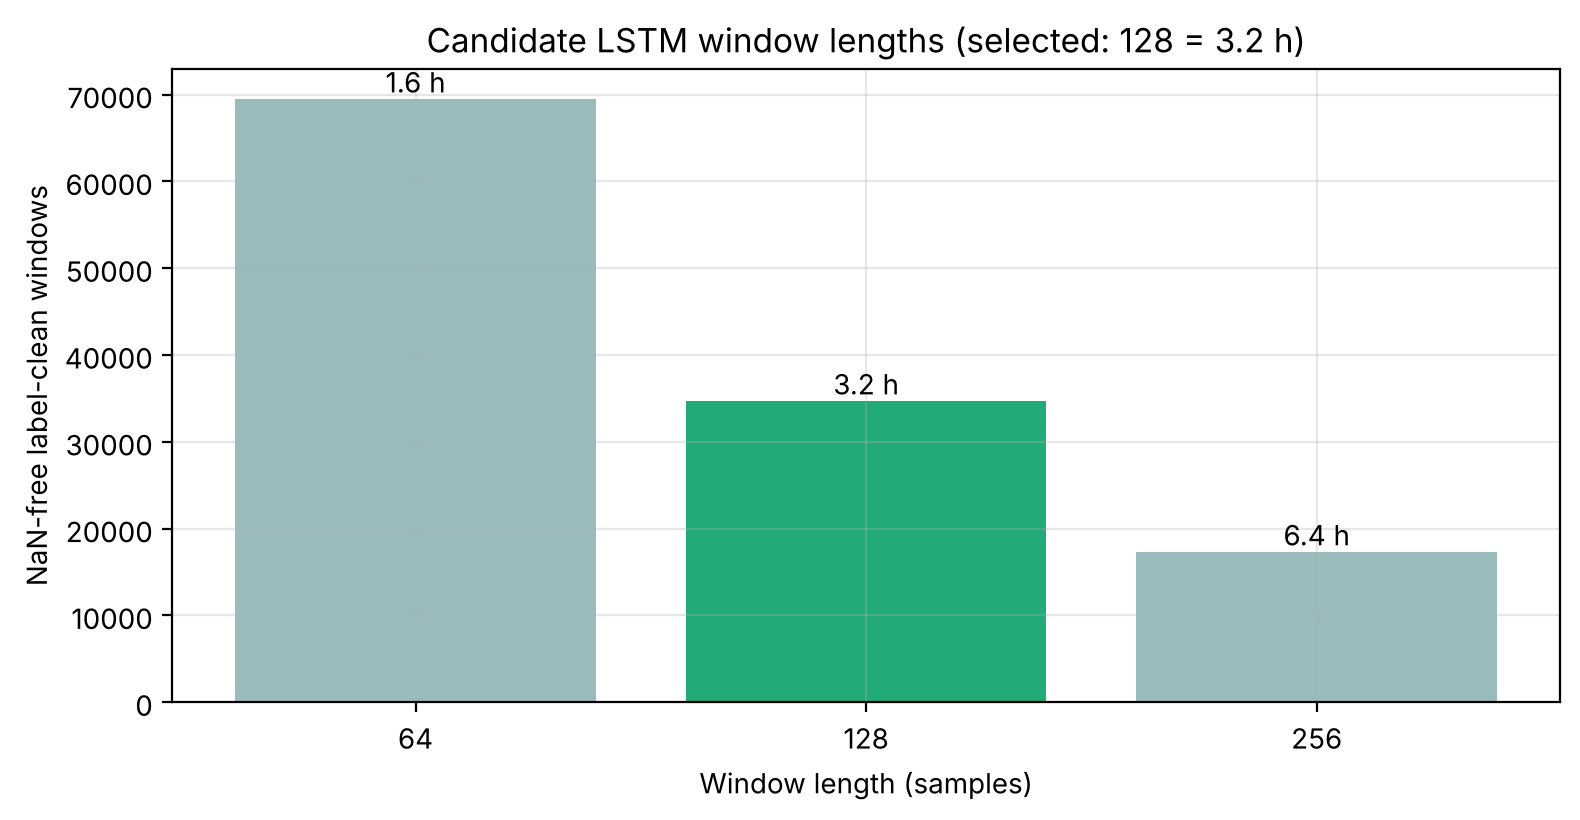

In [10]:
values = telemetry_df.to_numpy()
win_rows = []
for wlen in [64, 128, 256]:
    usable = clean_segments[clean_segments["Length"] >= wlen]
    total = valid = 0
    for s, L in zip(starts, ends - starts):
        for k in range(L // wlen):
            total += 1
            valid += not np.isnan(values[s + k * wlen: s + (k + 1) * wlen]).any()
    win_rows.append({"Window": wlen, "Hours": wlen * 1.5 / 60, "Usable_segments": len(usable),
                     "Candidate_windows": total, "NaN-free_windows": valid,
                     "NaN-free_%": round(valid / total * 100, 2)})
window_df = pd.DataFrame(win_rows)
print(window_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(window_df["Window"].astype(str), window_df["NaN-free_windows"], color=["#9bb", "#2a7", "#9bb"])
for i, r in window_df.iterrows():
    ax.text(i, r["NaN-free_windows"], f'{r["Hours"]:.1f} h', ha="center", va="bottom")
ax.set_xlabel("Window length (samples)"); ax.set_ylabel("NaN-free label-clean windows")
ax.set_title("Candidate LSTM window lengths (selected: 128 = 3.2 h)")
save_show("05_candidate_lstm_window_lengths.png")

## 10. Save all Course 1 outputs

In [11]:
telemetry_df.to_parquet(OUT / "02_preprocessing" / "telemetry_90s_12channels.parquet")
pd.DataFrame({"known_anomaly": known_mask}, index=telemetry_df.index).to_parquet(OUT / "02_preprocessing" / "known_anomaly_mask.parquet")
clean_segments.to_csv(OUT / "02_preprocessing" / "label_clean_segments.csv", index=False)
channel_summary.to_csv(OUT / "02_preprocessing" / "channel_alignment_and_missing_summary.csv", index=False)
coverage_df.to_csv(OUT / "02_preprocessing" / "resolution_coverage_comparison.csv", index=False)
window_df.to_csv(OUT / "02_preprocessing" / "lstm_window_comparison.csv", index=False)
sel_meta.to_csv(OUT / "01_dataset" / "selected_channel_metadata.csv", index=False)
sel_labels.to_csv(OUT / "01_dataset" / "selected_anomaly_labels.csv", index=False)
split_ids.to_csv(OUT / "03_splits" / "anomaly_event_split.csv", index=False)
split_summary.to_csv(OUT / "03_splits" / "split_summary.csv", index=False)

summary = pd.DataFrame({"Parameter": [
    "Dataset", "Selected channels", "Time resolution", "Interpolation rule", "Telemetry rows",
    "Telemetry period", "Anomaly events", "Annotation records", "Event split (train/val/test)",
    "Known-anomaly coverage (%)", "Label-clean segments", "LSTM window", "NaN-free 128-sample clean windows"],
  "Value": [
    "ESA-ADB Mission 1", len(SELECTED_CHANNELS), "90 seconds", "gaps <= 3 samples (4.5 min) only; longer gaps left missing",
    len(telemetry_df), f"{telemetry_df.index.min()} -> {telemetry_df.index.max()}", sel_labels["ID"].nunique(), len(sel_labels),
    "/".join(str(v) for v in split_summary["Anomaly_IDs"]), round(known_mask.mean() * 100, 3), len(clean_segments),
    "128 samples (3.2 h)", int(window_df.loc[window_df.Window == 128, "NaN-free_windows"].iloc[0])]})
summary.to_csv(OUT / "02_preprocessing" / "preprocessing_summary.csv", index=False)
print(summary.to_string(index=False))
for p in sorted(OUT.rglob("*")):
    if p.is_file() and p.parts[-2] in {"01_dataset", "02_preprocessing", "03_splits", "04_plots"}:
        print(f"{p.relative_to(OUT)}  ({p.stat().st_size/1e6:.2f} MB)")

                        Parameter                                                      Value
                          Dataset                                          ESA-ADB Mission 1
                Selected channels                                                         12
                  Time resolution                                                 90 seconds
               Interpolation rule gaps <= 3 samples (4.5 min) only; longer gaps left missing
                   Telemetry rows                                                    4909440
                 Telemetry period                 2000-01-01 00:00:00 -> 2013-12-31 23:58:30
                   Anomaly events                                                        168
               Annotation records                                                       1306
     Event split (train/val/test)                                                  117/25/26
       Known-anomaly coverage (%)                                     